#  Credit Card Fraud Detection using Machine Learning

## Project Overview

This project develops a supervised machine learning pipeline to detect fraudulent credit card transactions using the European Credit Card Fraud Detection dataset.

The notebook covers:

- Data Cleaning
- Exploratory Data Analysis (EDA)
- Feature Scaling
- Handling Class Imbalance using RandomUnderSampler
- Model Training
- Model Comparison
- Model Evaluation
- Model Persistence

Dataset:
European Credit Card Fraud Detection Dataset

Libraries:
Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Imbalanced-learn, Joblib

Objective:
Develop a reliable fraud detection model while addressing severe class imbalance.

# Import Libraries

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from imblearn.under_sampling import RandomUnderSampler


warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

# Load dataset

In [42]:
dataset_path = "data/creditcard.csv"
df = pd.read_csv(dataset_path)

# Dataset Overview

In [43]:
df.shape

(284807, 31)

In [44]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [45]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,-1.040458,-0.031513,-0.188093,-0.084316,0.041333,-0.302620,-0.660377,0.167430,-0.256117,0.382948,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [46]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

# Data Cleaning

### Missing Values

In [48]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### Duplicates

In [49]:
duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)


Number of Duplicate Rows: 1081


### Remove duplicates

In [50]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (283726, 31)


# Exploratory Data Analysis

### Class Distribution

In [51]:
 #Target Variable Distribution
class_counts = df["Class"].value_counts().sort_index()
print(class_counts)
 #Target class percentage
class_percentage = (class_counts / len(df) * 100).round(2)
print(class_percentage)

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.83
1     0.17
Name: count, dtype: float64


### Transaction Amount Distribution

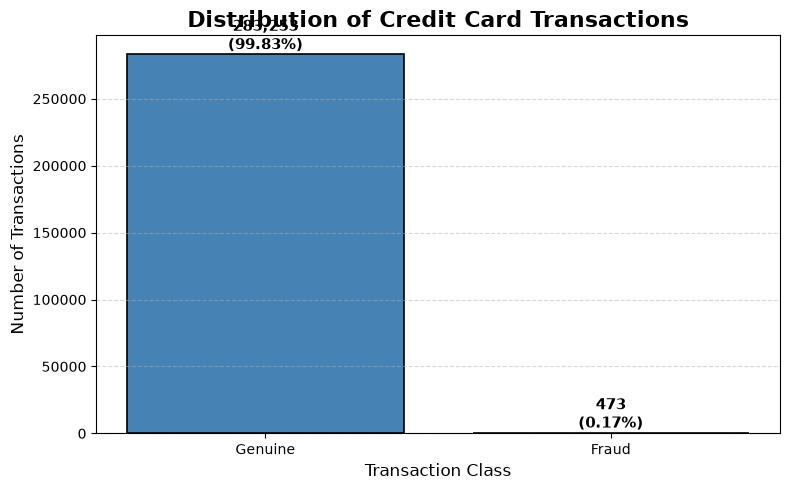

In [52]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    ["Genuine", "Fraud"],
    class_counts.values,
    color=["steelblue", "tomato"],
    edgecolor="black",
    linewidth=1.2
)
plt.title(
    "Distribution of Credit Card Transactions",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{class_counts.iloc[i]:,}\n({class_percentage.iloc[i]:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )
plt.tight_layout()
plt.show()

### Observation

- The dataset is extremely imbalanced, with genuine transactions accounting for approximately **99.83%** of all observations and fraudulent transactions representing only **0.17%**.
- Such severe class imbalance can bias machine learning models toward predicting the majority class, resulting in poor fraud detection performance.
- A high classification accuracy alone would therefore be misleading, as a model predicting every transaction as genuine would still achieve very high accuracy.
- This imbalance justifies the use of **RandomUnderSampler** during model training to create a more balanced learning dataset.
- Precision, Recall, F1-Score, and ROC-AUC are more appropriate evaluation metrics than accuracy for this classification problem.

 
### Transaction Amount by Class 


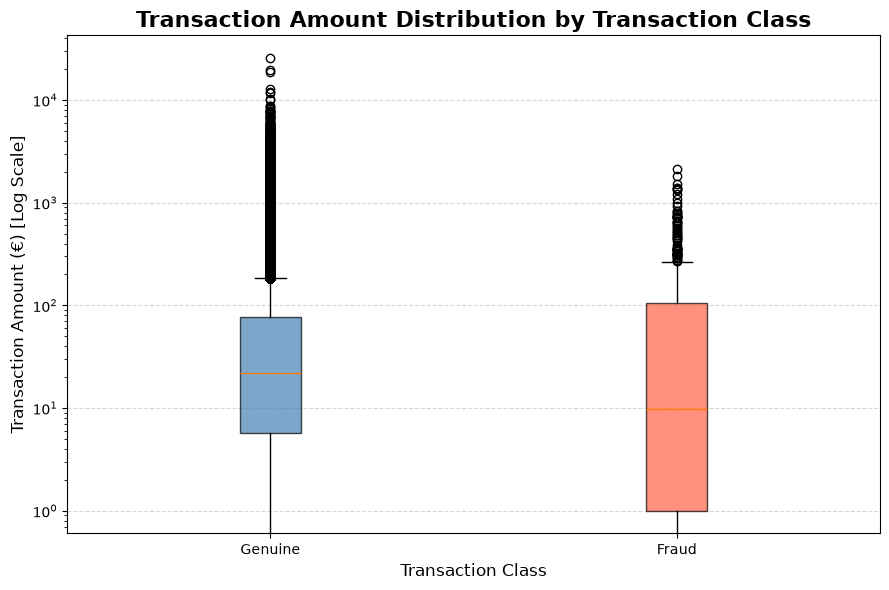

In [53]:
plt.figure(figsize=(9, 6))
box = plt.boxplot(
    [
        df[df["Class"] == 0]["Amount"],
        df[df["Class"] == 1]["Amount"]
    ],
    tick_labels=["Genuine", "Fraud"],
    patch_artist=True,
    showfliers=True
)
# Box Colors
colors = ["steelblue", "tomato"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
plt.yscale("log")   
plt.title(
    "Transaction Amount Distribution by Transaction Class",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Transaction Amount (€) [Log Scale]", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Observation

- The transaction amount distribution is highly right-skewed for both genuine and fraudulent transactions.
- A logarithmic scale has been applied to improve visualization across the wide range of transaction amounts.
- Genuine transactions exhibit a broader spread with numerous high-value outliers, reflecting the natural variability of legitimate customer spending.
- Fraudulent transactions generally involve lower transaction amounts, although a few high-value fraudulent transactions are also present.
- The overlap between the two classes indicates that transaction amount alone is insufficient for fraud detection, reinforcing the need for additional predictive features 

### Transaction Time Distribution

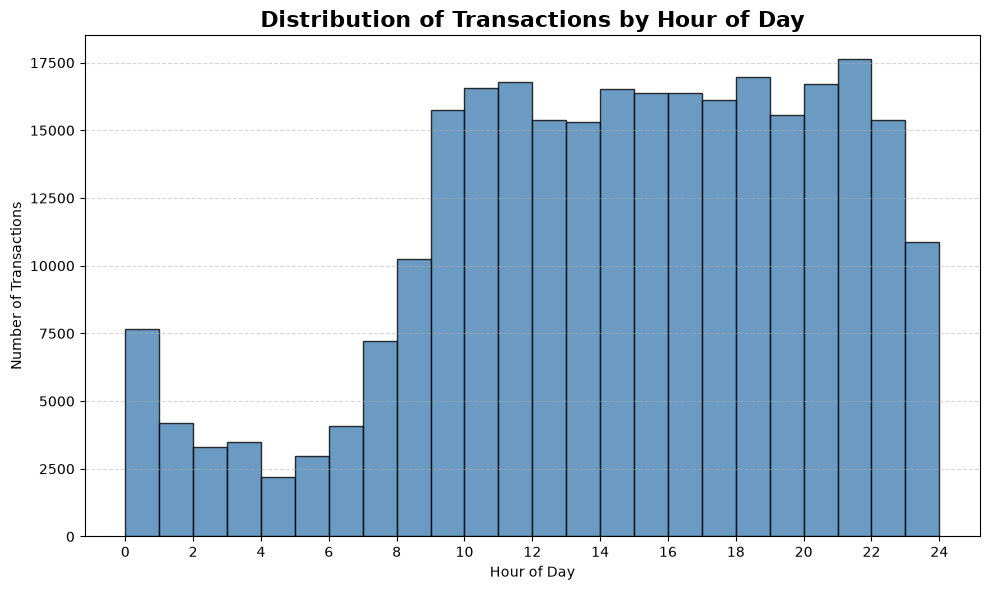

In [54]:
hour = (df["Time"] % 86400) / 3600
plt.figure(figsize=(10, 6))
plt.hist(
    hour,
    bins=24,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)
plt.title(
    "Distribution of Transactions by Hour of Day",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(0, 25, 2))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Observation

- Transaction activity varies throughout the day rather than being uniformly distributed.
- Higher transaction volumes are observed during daytime and evening hours, reflecting normal customer spending behavior.
- Transaction frequency decreases during late-night and early-morning hours, indicating reduced customer activity.
- Converting elapsed seconds into hours of the day provides a more intuitive understanding of transaction timing than using raw timestamps.
- Time-based patterns may contribute useful information for fraud detection when combined with other predictive features.

### Transaction Amount Distribution by Class

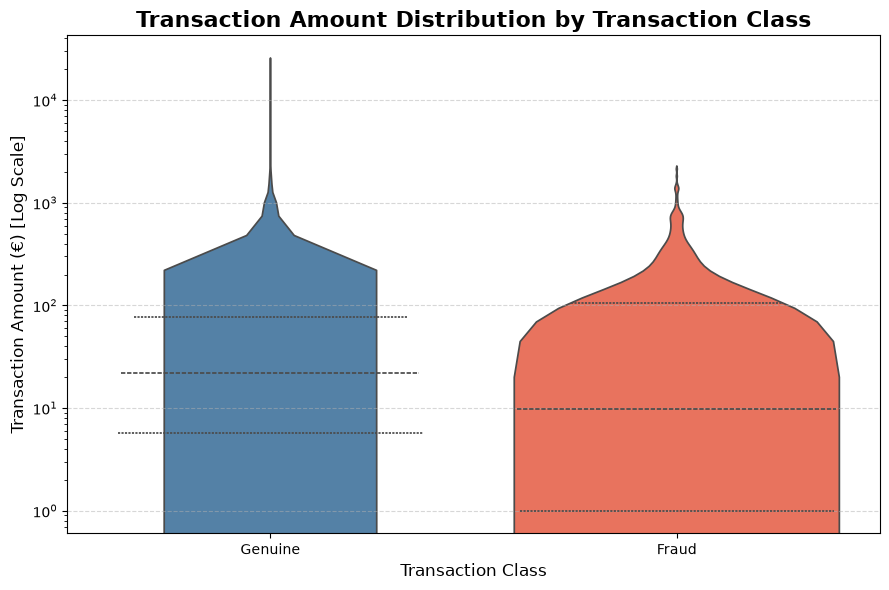

In [55]:
plt.figure(figsize=(9, 6))
sns.violinplot(
    data=df,
    x="Class",
    y="Amount",
    hue="Class",
    palette=["steelblue", "tomato"],
    legend=False,
    inner="quartile"
)
plt.yscale("log")
plt.title(
    "Transaction Amount Distribution by Transaction Class",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Transaction Amount (€) [Log Scale]", fontsize=12)
plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Observation

- The violin plot illustrates both the distribution density and the spread of transaction amounts for genuine and fraudulent transactions.
- A logarithmic scale has been applied to better visualize the highly right-skewed transaction amounts.
- Genuine transactions exhibit a wider distribution and greater variability, while fraudulent transactions are generally concentrated at lower transaction amounts.
- The embedded quartile markers provide additional insight into the median and interquartile range of each transaction class.
- Compared with the boxplot, the violin plot reveals the underlying density of the data, offering a more detailed view of transaction amount distributions.

# Statistical Comparison

In [56]:
df.groupby("Class").describe()

Time                                                       \
          count          mean           std    min      25%      50%   
Class                                                                  
0      283253.0  94835.058093  47475.550607    0.0  54233.0  84711.0   
1         473.0  80450.513742  48636.179973  406.0  41203.0  73408.0   

                                 V1                                          \
            75%       max     count      mean       std       min       25%   
Class                                                                         
0      139308.0  172792.0  283253.0  0.013439  1.922179 -56.40751 -0.913431   
1      129095.0  170348.0     473.0 -4.498280  6.593145 -30.55238 -5.603690   

                                           V2                                \
            50%       75%       max     count      mean      std        min   
Class                                                                         
0      0.022562  1.316788  2.454930  283253.0 -0.009829  1.63352 -72.715728   
1     -2.271755 -0.361428  2.132386     473.0  3.405965  4.12250  -8.402154   

                                                      V3                      \
            25%       50%       75%        max     count      mean       std   
Class                                                                          
0     -0.601398  0.062561  0.797012  18.902453  283253.0  0.012853  1.457593   
1      1.145381  2.617105  4.571743  22.057729     473.0 -6.729599  6.909647   

                                                                V4            \
             min       25%       50%       75%       max     count      mean   
Class                                                                          
0     -48.325589 -0.883966  0.182247  1.028261  9.382558  283253.0 -0.010440   
1     -31.103685 -7.926507 -4.875397 -2.171454  2.250210     473.0  4.472591   

                                                                          V5  \
            std       min       25%       50%       75%        max     count   
Class                                                                          
0      1.398575 -5.683171 -0.851605 -0.024500  0.734231  16.875344  283253.0   
1      2.871523 -1.313275  2.288644  4.100098  6.290918  12.114672     473.0   

                                                                     \
           mean       std         min       25%       50%       75%   
Class                                                                 
0      0.006769  1.355816 -113.743307 -0.687888 -0.052807  0.612442   
1     -2.957197  5.278831  -22.105532 -4.278983 -1.372245  0.260821   

                        V6                                                     \
             max     count      mean       std        min       25%       50%   
Class                                                                           
0      34.801666  283253.0  0.001251  1.329914 -26.160506 -0.767543 -0.274172   
1      11.095089     473.0 -1.432518  1.715347  -6.406267 -2.450444 -1.420468   

                                  V7                                           \
            75%        max     count      mean       std        min       25%   
Class                                                                           
0      0.397678  73.301626  283253.0  0.010447  1.177480 -31.764946 -0.550146   
1     -0.413647   6.474115     473.0 -5.175912  6.858024 -43.557242 -6.989195   

                                             V8                                \
            50%       75%         max     count      mean      std        min   
Class                                                                           
0      0.041664  0.571029  120.589494  283253.0 -0.002448  1.15714 -73.216718   
1     -2.902079 -0.907188    5.802537     473.0  0.953255  5.58595 -41.044261   

                                                      V9                      \
 

In [57]:
print(df.groupby("Class")["Amount"].mean())

Class
0     88.413575
1    123.871860
Name: Amount, dtype: float64


### Mean vs Median Transaction Amount By Class

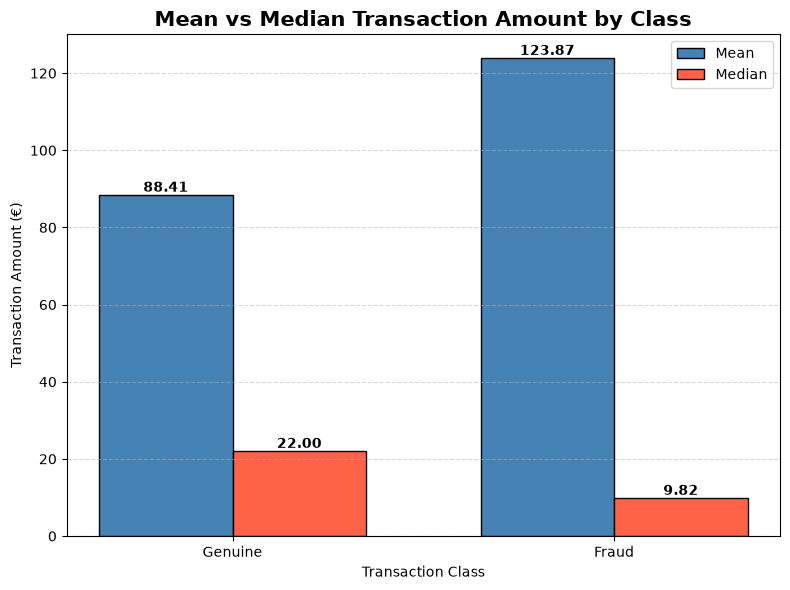

In [58]:
# Calculate Mean and Median
amount_stats = df.groupby("Class")["Amount"].agg(["mean", "median"])
labels = ["Genuine", "Fraud"]
x = np.arange(len(labels))
width = 0.35
plt.figure(figsize=(8, 6))
plt.bar(
    x - width/2,
    amount_stats["mean"],
    width,
    label="Mean",
    color="steelblue",
    edgecolor="black"
)
plt.bar(
    x + width/2,
    amount_stats["median"],
    width,
    label="Median",
    color="tomato",
    edgecolor="black"
)
plt.xticks(x, labels)
plt.title(
    "Mean vs Median Transaction Amount by Class",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount (€)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
# Value labels
for i, value in enumerate(amount_stats["mean"]):
    plt.text(
        x[i] - width/2,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )
for i, value in enumerate(amount_stats["median"]):
    plt.text(
        x[i] + width/2,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )
plt.tight_layout()
plt.show()

### Observation

- Both the mean and median transaction amounts are compared to better understand the distribution of transaction values.
- The difference between the mean and median indicates that transaction amounts are highly right-skewed, with a small number of high-value transactions increasing the mean.
- Genuine transactions generally exhibit higher average transaction amounts than fraudulent transactions.
- The median provides a more robust measure of central tendency because it is less affected by extreme outliers.
- Comparing both statistics offers a more complete understanding of transaction behavior than relying on the mean alone.

### Correlation Analysis

In [59]:
correlation_matrix = df.corr()

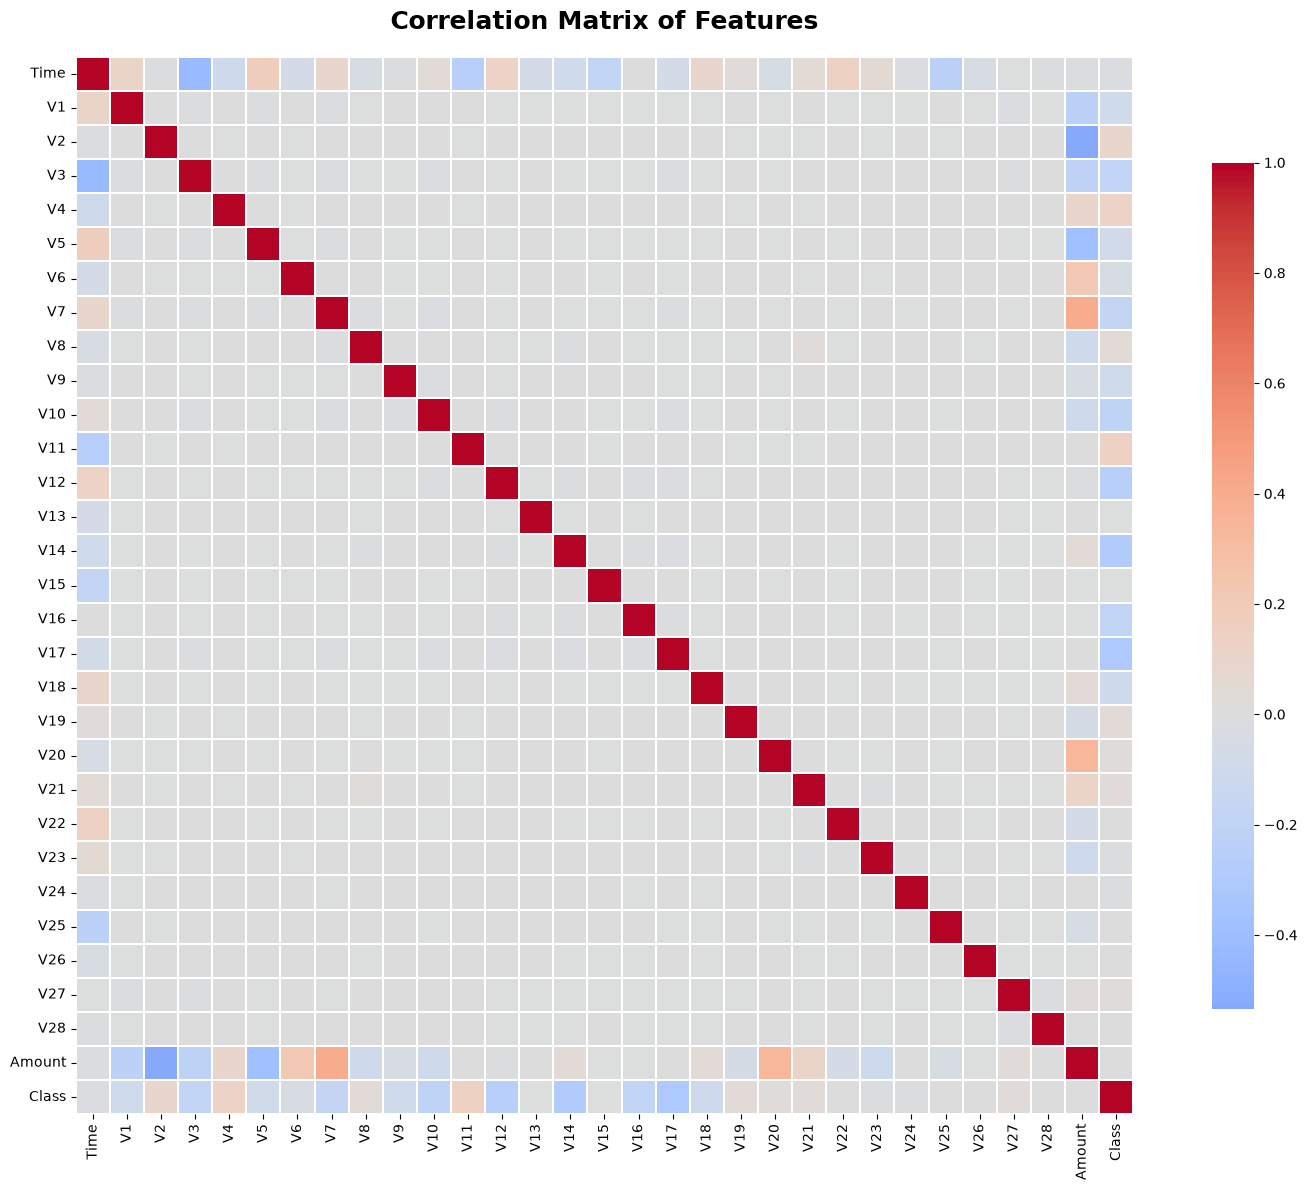

In [60]:
# Correlation Matrix
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8}
)
plt.title(
    "Correlation Matrix of Features",
    fontsize=18,
    fontweight="bold",
    pad=20
)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

- The correlation heatmap illustrates the pairwise relationships among all numerical features in the dataset.
- Most PCA-transformed features exhibit relatively weak correlations with one another, indicating limited multicollinearity.
- The **Time** and **Amount** features also show only weak linear relationships with the majority of transformed features.
- The absence of strong correlations between most predictors suggests that each feature contributes unique information to the machine learning models.
- This correlation analysis provides an initial understanding of feature relationships before examining their individual association with the target variable.

### Correlation of Features with Target Variable

In [61]:
class_correlation = df.corr()["Class"].sort_values(ascending=False)

### Correlation of Features with Fraud Class

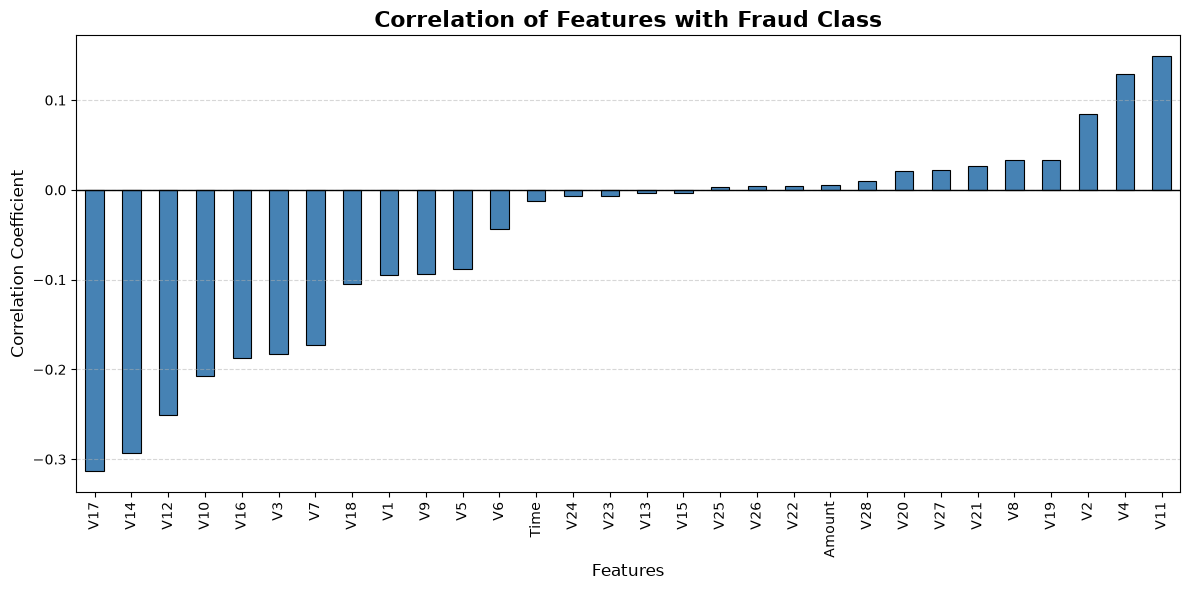

In [62]:
plt.figure(figsize=(12, 6))
class_correlation.drop("Class").sort_values().plot(
    kind="bar",
    color="steelblue",
    edgecolor="black",
    linewidth=0.8
)
plt.title(
    "Correlation of Features with Fraud Class",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Correlation Coefficient", fontsize=12)
plt.axhline(0, color="black", linewidth=1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Observation

- The chart illustrates the correlation between each feature and the target variable (Fraud Class).
- Most PCA-transformed features exhibit relatively weak individual correlations with the target, indicating that fraud detection relies on the combined influence of multiple variables rather than a single dominant feature.
- Features with larger positive or negative correlation coefficients are likely to contribute more strongly to distinguishing fraudulent transactions.
- Although correlation provides useful preliminary insights, machine learning models are capable of capturing more complex and non-linear relationships among features.
- The most strongly correlated features identified here will be further examined during feature importance analysis using tree-based models.

In [63]:
# Top 3 features most correlated with the fraud class
top_features = (
    class_correlation
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
    .head(3)
)

print(top_features)

V17    0.313498
V14    0.293375
V12    0.250711
Name: Class, dtype: float64


## Distribution of the Most Correlated Features

The correlation analysis identified **V17**, **V14**, and **V12** as the three features with the strongest relationship to the target variable (**Fraud Class**).

To better understand why these features are important, their distributions are compared across genuine and fraudulent transactions. Visualizing these distributions helps determine whether the two classes occupy different regions of the feature space, providing insight into their predictive power.

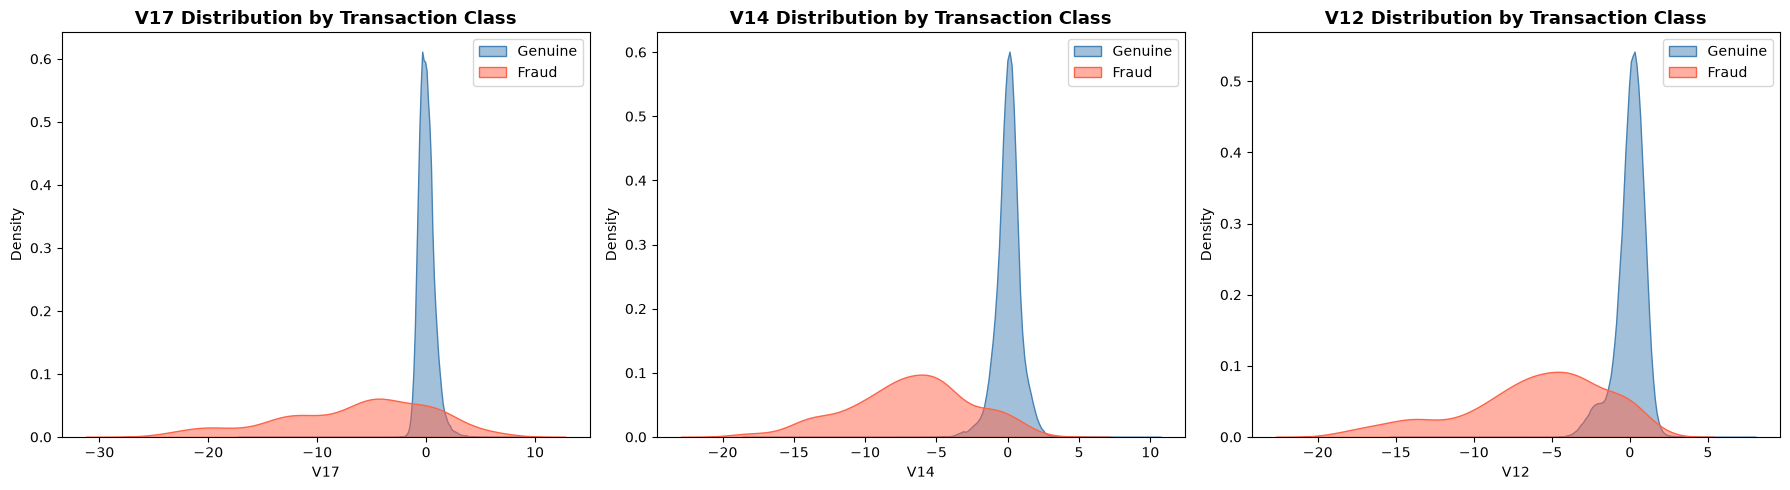

In [64]:
top_features = ["V17", "V14", "V12"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, top_features):

    sns.kdeplot(
        data=df[df["Class"] == 0],
        x=feature,
        fill=True,
        color="steelblue",
        alpha=0.5,
        label="Genuine",
        ax=ax
    )

    sns.kdeplot(
        data=df[df["Class"] == 1],
        x=feature,
        fill=True,
        color="tomato",
        alpha=0.5,
        label="Fraud",
        ax=ax
    )

    ax.set_title(
        f"{feature} Distribution by Transaction Class",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

### Observation

- V17, V14, and V12 exhibit the strongest correlation with the target variable among all transformed features.
- The density distributions of fraudulent transactions differ noticeably from those of genuine transactions, indicating that these features possess strong discriminative power.
- Fraudulent transactions are concentrated within specific value ranges, whereas genuine transactions display broader and more dispersed distributions.
- Although some overlap exists between the two classes, these features provide meaningful separation that can be effectively exploited by machine learning models.
- These findings are consistent with the earlier correlation analysis and help explain why these variables contribute significantly to fraud detection performance.

## Outlier Detection using IQR Method

### Boxplot Before Outlier Detection

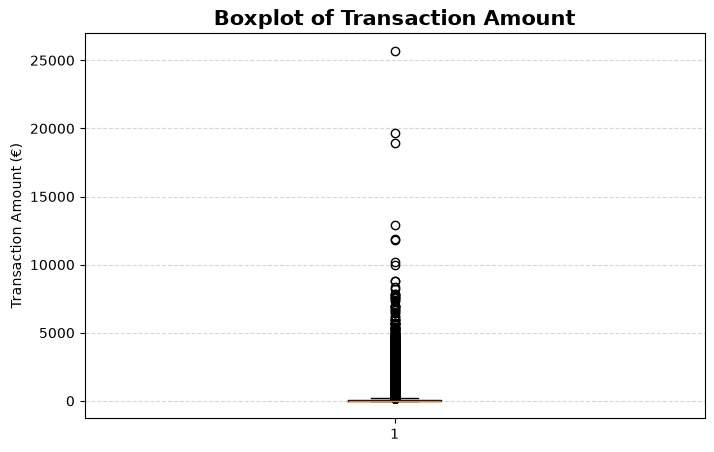

In [65]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["Amount"], vert=True)
plt.title("Boxplot of Transaction Amount", fontsize=15, fontweight="bold")
plt.ylabel("Transaction Amount (€)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Detecting outliers using IQR

In [66]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)
outliers = df[
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
]

### Number of Outliers

In [67]:
print("Number of Outliers:", len(outliers))

Number of Outliers: 31685


### Observation

- The IQR method identified a considerable number of potential outliers in the **Amount** feature.
- However, these observations were **not removed** from the dataset.
- In financial transaction data, unusually large or unusually small transactions may represent legitimate business activity or fraudulent behavior.
- Removing such observations could result in the loss of valuable fraud-related information and negatively impact the model's ability to detect anomalous transactions.
- Therefore, all observations were retained for subsequent analysis and model training.

# Feature Engineering

No additional feature engineering was required because the dataset already contains PCA-transformed features.

# Train-Test Split

In [68]:
X = df.drop("Class", axis=1)
y = df["Class"]
print("Feature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

Feature Matrix Shape: (283726, 30)
Target Vector Shape: (283726,)


In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Features:", X_train.shape)
print("Testing Features :", X_test.shape)
print("Training Labels  :", y_train.shape)
print("Testing Labels   :", y_test.shape)

Training Features: (226980, 30)
Testing Features : (56746, 30)
Training Labels  : (226980,)
Testing Labels   : (56746,)


# Feature Scaling

In [70]:
time_scaler = StandardScaler()
amount_scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train["Time"] = time_scaler.fit_transform(X_train[["Time"]])
X_test["Time"] = time_scaler.transform(X_test[["Time"]])
X_train["Amount"] = amount_scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = amount_scaler.transform(X_test[["Amount"]])
print("Feature scaling completed successfully.")

Feature scaling completed successfully.


# Baseline Model (Original Imbalanced Dataset)

In [71]:
baseline_model = LogisticRegression(random_state=42, max_iter=1000)
baseline_model.fit(X_train, y_train)
print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


### Make Predictions

In [72]:
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

### Model Evaluation

In [73]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9991
Precision: 0.8485
Recall   : 0.5895
F1 Score : 0.6957
ROC-AUC  : 0.9563


### Confusion Matrix

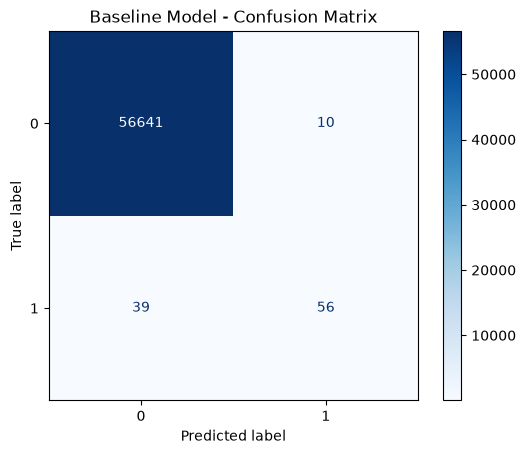

In [74]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Baseline Model - Confusion Matrix")
plt.show()

# Handling Class Imbalance using RandomUnderSampler

### RandomUnderSampler (20:1)

In [75]:
rus = RandomUnderSampler(
    sampling_strategy=1/20,
    random_state=42
)
X_train_rus, y_train_rus = rus.fit_resample(
    X_train,
    y_train
)
print("Original Training Set:")
print(y_train.value_counts())
print("\nAfter RandomUnderSampler (20:1):")
print(y_train_rus.value_counts())

Original Training Set:
Class
0    226602
1       378
Name: count, dtype: int64

After RandomUnderSampler (20:1):
Class
0    7560
1     378
Name: count, dtype: int64


### Logistic Regression (20:1)

In [76]:
# moodel training 
model_20 = LogisticRegression(
    random_state=42,
    max_iter=1000
)
model_20.fit(X_train_rus, y_train_rus)
print("Model trained successfully.")
# Predictions
y_pred_20 = model_20.predict(X_test)
y_prob_20 = model_20.predict_proba(X_test)[:, 1]
# Model Evaluation
accuracy_20 = accuracy_score(y_test, y_pred_20)
precision_20 = precision_score(y_test, y_pred_20)
recall_20 = recall_score(y_test, y_pred_20)
f1_20 = f1_score(y_test, y_pred_20)
roc_auc_20 = roc_auc_score(y_test, y_prob_20)
print(f"Accuracy : {accuracy_20:.4f}")
print(f"Precision: {precision_20:.4f}")
print(f"Recall   : {recall_20:.4f}")
print(f"F1 Score : {f1_20:.4f}")
print(f"ROC-AUC  : {roc_auc_20:.4f}")

Model trained successfully.
Accuracy : 0.9985
Precision: 0.5319
Recall   : 0.7895
F1 Score : 0.6356
ROC-AUC  : 0.9657


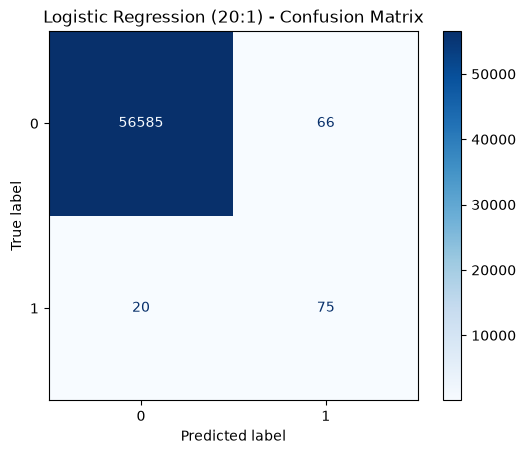

In [77]:
cm = confusion_matrix(y_test, y_pred_20)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap="Blues")

plt.title("Logistic Regression (20:1) - Confusion Matrix")

plt.show()

### Logistic Regression (10:1)

Model trained successfully.
Accuracy : 0.9965
Precision: 0.2962
Recall   : 0.8105
F1 Score : 0.4338
ROC AUC  : 0.9633


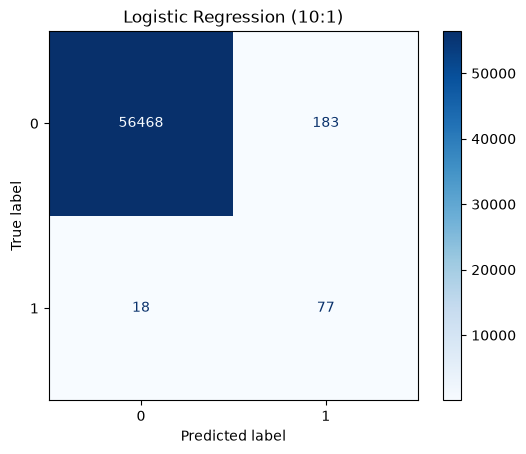

In [78]:
# model training
rus = RandomUnderSampler(
    sampling_strategy=1/10,
    random_state=42
)
X_train_10, y_train_10 = rus.fit_resample(X_train, y_train)
model_10 = LogisticRegression(random_state=42,max_iter=1000)
model_10.fit(X_train_10,y_train_10)
print("Model trained successfully.")
# model prediction
y_pred_10 = model_10.predict(X_test)
y_prob_10 = model_10.predict_proba(X_test)[:,1]
# model evaluation
accuracy_10 = accuracy_score(y_test,y_pred_10)
precision_10 = precision_score(y_test,y_pred_10)
recall_10 = recall_score(y_test,y_pred_10)
f1_10 = f1_score(y_test,y_pred_10)
roc_auc_10 = roc_auc_score(y_test,y_prob_10)
print(f"Accuracy : {accuracy_10:.4f}")
print(f"Precision: {precision_10:.4f}")
print(f"Recall   : {recall_10:.4f}")
print(f"F1 Score : {f1_10:.4f}")
print(f"ROC AUC  : {roc_auc_10:.4f}")
# confusion matrix and display
cm=confusion_matrix(y_test,y_pred_10)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Logistic Regression (10:1)")
plt.show()

### Logistic Regression (5:1)

Accuracy : 0.9943
Precision: 0.2052
Recall   : 0.8316
F1 Score : 0.3292
ROC AUC  : 0.9587


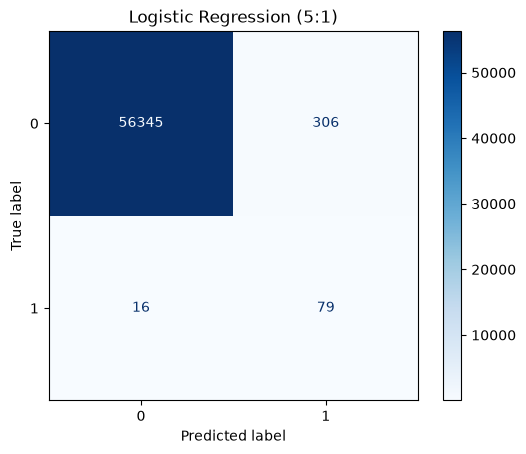

In [79]:
rus = RandomUnderSampler(
    sampling_strategy=1/5,
    random_state=42
)
# model training
X_train_5, y_train_5 = rus.fit_resample(X_train, y_train)
model_5 = LogisticRegression(random_state=42,max_iter=1000)
model_5.fit(X_train_5,y_train_5)
# model prediction
y_pred_5 = model_5.predict(X_test)
y_prob_5 = model_5.predict_proba(X_test)[:,1]
# model evaluation
accuracy_5 = accuracy_score(y_test,y_pred_5)
precision_5 = precision_score(y_test,y_pred_5)
recall_5 = recall_score(y_test,y_pred_5)
f1_5 = f1_score(y_test,y_pred_5)
roc_auc_5 = roc_auc_score(y_test,y_prob_5)
print(f"Accuracy : {accuracy_5:.4f}")
print(f"Precision: {precision_5:.4f}")
print(f"Recall   : {recall_5:.4f}")
print(f"F1 Score : {f1_5:.4f}")
print(f"ROC AUC  : {roc_auc_5:.4f}")
# confusion matrix and display
cm=confusion_matrix(y_test,y_pred_5)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Logistic Regression (5:1)")
plt.show()

### Logistic Regression (1:1)

Accuracy : 0.9731
Precision: 0.0519
Recall   : 0.8737
F1 Score : 0.0980
ROC AUC  : 0.9559


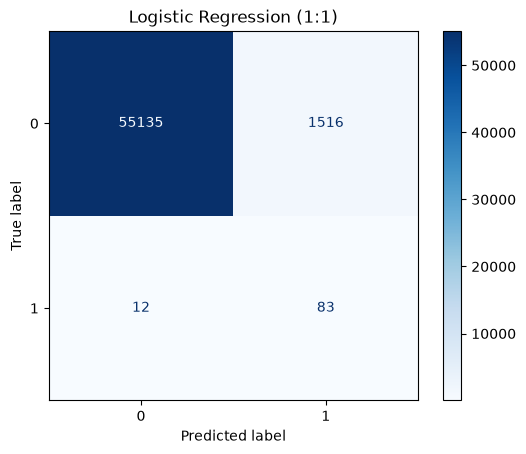

In [80]:
rus = RandomUnderSampler(
    sampling_strategy=1,
    random_state=42
)
# model training
X_train_1, y_train_1 = rus.fit_resample(X_train, y_train)
model_1 = LogisticRegression(random_state=42,max_iter=1000)
model_1.fit(X_train_1,y_train_1)
# model prediction
y_pred_1 = model_1.predict(X_test)
y_prob_1 = model_1.predict_proba(X_test)[:,1]
# model evaluation
accuracy_1 = accuracy_score(y_test,y_pred_1)
precision_1 = precision_score(y_test,y_pred_1)
recall_1 = recall_score(y_test,y_pred_1)
f1_1 = f1_score(y_test,y_pred_1)
roc_auc_1 = roc_auc_score(y_test,y_prob_1)
print(f"Accuracy : {accuracy_1:.4f}")
print(f"Precision: {precision_1:.4f}")
print(f"Recall   : {recall_1:.4f}")
print(f"F1 Score : {f1_1:.4f}")
print(f"ROC AUC  : {roc_auc_1:.4f}")
# confusion matrix and display
cm=confusion_matrix(y_test,y_pred_1)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Logistic Regression (1:1)")
plt.show()

#  Comparison of Sampling Ratios

In [81]:
comparison = pd.DataFrame({
    "Dataset":[
        "Original",
        "20:1",
        "10:1",
        "5:1",
        "1:1"
    ],
    "Accuracy":[
        accuracy,
        accuracy_20,
        accuracy_10,
        accuracy_5,
        accuracy_1
    ],
    "Precision":[
        precision,
        precision_20,
        precision_10,
        precision_5,
        precision_1
    ],
    "Recall":[
        recall,
        recall_20,
        recall_10,
        recall_5,
        recall_1
    ],
    "F1 Score":[
        f1,
        f1_20,
        f1_10,
        f1_5,
        f1_1
    ],
    "ROC AUC":[
        roc_auc,
        roc_auc_20,
        roc_auc_10,
        roc_auc_5,
        roc_auc_1
    ]
})
comparison

,Dataset,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Original,0.999137,0.848485,0.589474,0.695652,0.956345
1,20:1,0.998484,0.531915,0.789474,0.635593,0.965658
2,10:1,0.996458,0.296154,0.810526,0.433803,0.963256
3,5:1,0.994326,0.205195,0.831579,0.329167,0.958749
4,1:1,0.973073,0.051907,0.873684,0.097993,0.955867


## Why was the 20:1 RandomUnderSampler ratio used for all models?

Several undersampling ratios (20:1, 10:1, 5:1, and 1:1) were initially evaluated using Logistic Regression.

Among these, the 20:1 ratio provided the most practical balance between fraud detection performance and false positive rate. While lower ratios slightly improved recall, they caused a significant reduction in precision, resulting in many additional false alarms.

To maintain consistency and enable fair comparison across different classifiers, the selected 20:1 ratio was subsequently used for Decision Tree and Random Forest training.

## Decision Tree Classifier (RandomUnderSampler 20:1)

In [82]:
# Train Decision Tree Model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)
decision_tree_model.fit(
    X_train_rus,
    y_train_rus
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [83]:
# Decision Tree Prediction
y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

In [84]:
# Decision Tree Evaluation
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1 Score : {f1_dt:.4f}")
print(f"ROC AUC  : {roc_auc_dt:.4f}")

Accuracy : 0.9916
Precision: 0.1418
Recall   : 0.7895
F1 Score : 0.2404
ROC AUC  : 0.8907


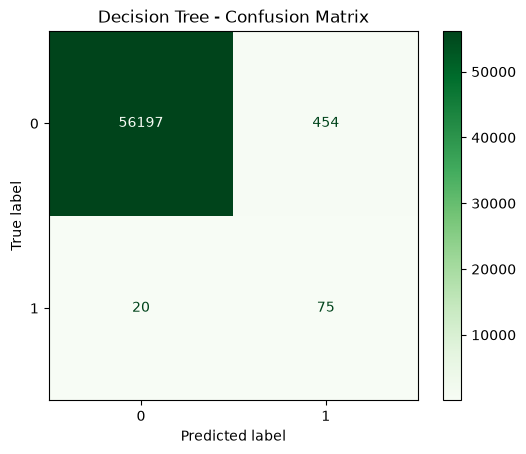

In [85]:

# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt)
disp.plot(cmap="Greens")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

# Random Forest Classifier

In [86]:
# Train Random Forest on the
# RandomUnderSampler (20:1) Dataset
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
random_forest_model.fit(
    X_train_rus,
    y_train_rus
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [87]:
# Random Forest Prediction
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [88]:
# Random Forest Evaluation 
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC AUC  : {roc_auc_rf:.4f}")

Accuracy : 0.9992
Precision: 0.7400
Recall   : 0.7789
F1 Score : 0.7590
ROC AUC  : 0.9635


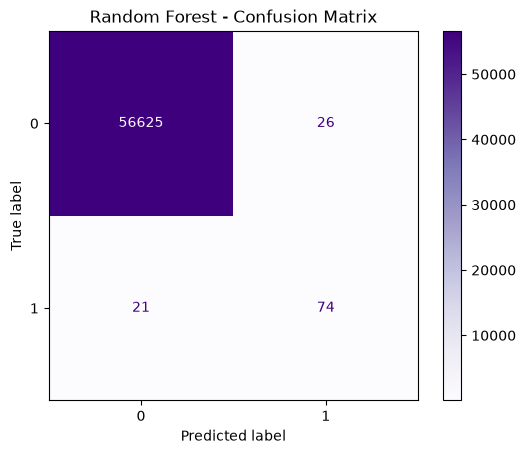

In [89]:
# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot(cmap="Purples")
plt.title("Random Forest - Confusion Matrix")
plt.show()

# Model Performance Comparison

In [90]:
# Model Comparison Table
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_20,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision_20,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall_20,
        recall_dt,
        recall_rf
    ],
    "F1 Score": [
        f1_20,
        f1_dt,
        f1_rf
    ],
    "ROC AUC": [
        roc_auc_20,
        roc_auc_dt,
        roc_auc_rf
    ]
})
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.998484,0.531915,0.789474,0.635593,0.965658
1,Decision Tree,0.991647,0.141777,0.789474,0.240385,0.890730
2,Random Forest,0.999172,0.740000,0.778947,0.758974,0.963508


# Best Model Selection

In [91]:
# Best Performing Model
best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]
print(best_model)

Model        Random Forest
Accuracy          0.999172
Precision             0.74
Recall            0.778947
F1 Score          0.758974
ROC AUC           0.963508
Name: 2, dtype: object


# Performance Comparison Of Machine Learning Models

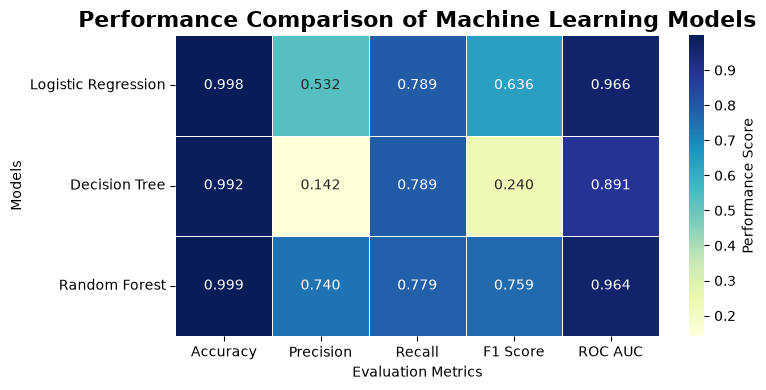

In [92]:
comparison_df_heatmap = comparison_df.set_index("Model")
plt.figure(figsize=(8, 4))
sns.heatmap(
    comparison_df_heatmap,
    annot=True,
    cmap="YlGnBu",
    fmt=".3f",
    linewidths=0.5,
    cbar_kws={"label": "Performance Score"}
)
plt.title(
    "Performance Comparison of Machine Learning Models",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Models")
plt.tight_layout()
plt.show()

### Observation

- The heatmap provides a comprehensive comparison of all evaluation metrics across the three machine learning models.
- Darker color intensities represent higher performance scores, allowing quick identification of the strongest-performing model for each metric.
- The Random Forest model consistently achieves the highest scores across most evaluation metrics, demonstrating its superior ability to distinguish fraudulent transactions from genuine ones.
- Logistic Regression serves as a strong baseline model, delivering competitive performance despite its relatively simple linear nature.
- Although the Decision Tree model performs reasonably well, its overall performance is less consistent than the Random Forest model, particularly across precision, F1-Score, and ROC-AUC.
- Based on the combined evaluation of Accuracy, Precision, Recall, F1-Score, and ROC-AUC, the Random Forest model was selected as the final model for deployment.

# ROC Curve Comparison

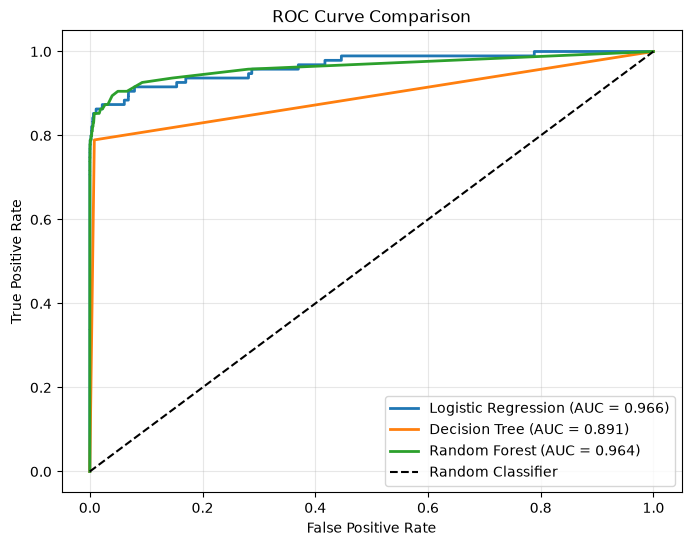

In [93]:
# ROC Curve Comparison
from sklearn.metrics import roc_curve
plt.figure(figsize=(8,6))
# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_20)
plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_20:.3f})",
    linewidth=2
)
# Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {roc_auc_dt:.3f})",
    linewidth=2
)
# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.3f})",
    linewidth=2
)
# Random Guess
plt.plot([0,1],[0,1],'k--',label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Precision-Recall Curve Comparison

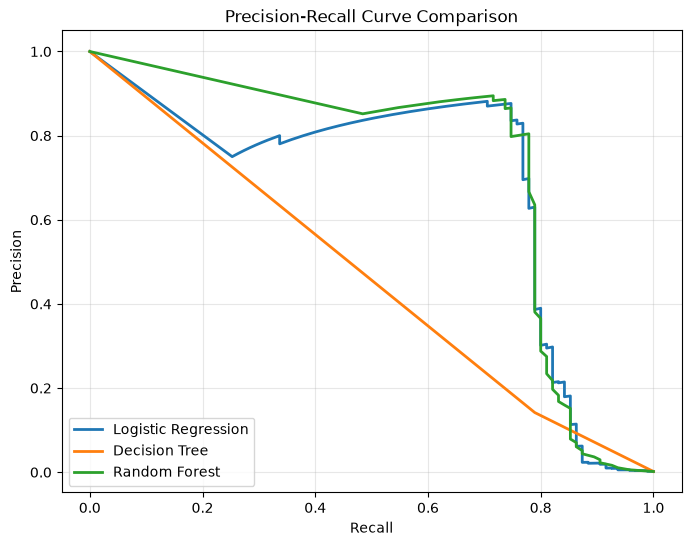

In [94]:
# Precision-Recall Curve Comparison
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(8,6))
# Logistic Regression
precision_lr, recall_lr_curve, _ = precision_recall_curve(y_test, y_prob_20)
plt.plot(
    recall_lr_curve,
    precision_lr,
    label="Logistic Regression",
    linewidth=2
)
# Decision Tree
precision_dt_curve, recall_dt_curve, _ = precision_recall_curve(y_test, y_prob_dt)
plt.plot(
    recall_dt_curve,
    precision_dt_curve,
    label="Decision Tree",
    linewidth=2
)
# Random Forest
precision_rf_curve, recall_rf_curve, _ = precision_recall_curve(y_test, y_prob_rf)
plt.plot(
    recall_rf_curve,
    precision_rf_curve,
    label="Random Forest",
    linewidth=2
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Feature Importance Analysis

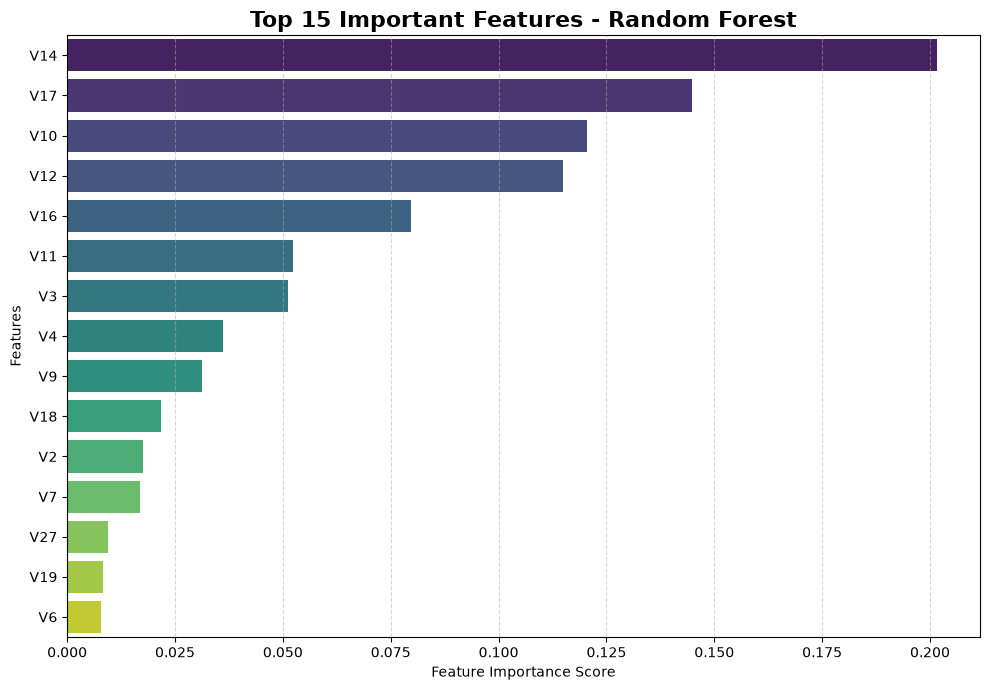

In [95]:
# Create DataFrame of feature importances
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})
# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
# Select Top 15 Features

top_features = feature_importance.head(15)
plt.figure(figsize=(10,7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)
plt.title(
    "Top 15 Important Features - Random Forest",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Final Model Selection

After evaluating the performance of all three machine learning models using multiple evaluation metrics, the **Random Forest classifier** was selected as the final model for this project.

The selection was based on its ability to achieve the best overall balance between **Precision**, **Recall**, **F1-Score**, and **ROC-AUC**, while maintaining excellent classification performance on the highly imbalanced fraud detection dataset.

Unlike Logistic Regression, Random Forest is capable of capturing complex non-linear relationships among features. Compared to a single Decision Tree, it provides better generalization and is less prone to overfitting due to its ensemble learning approach.

Furthermore, the Random Forest feature importance analysis demonstrated that the model relied on meaningful predictors such as **V17**, **V14**, and **V12**, which were also identified as highly correlated with fraudulent transactions during exploratory data analysis.

In [96]:
final_selection = pd.DataFrame({
    "Criteria": [
        "Best Overall Accuracy",
        "Best Precision",
        "Best Recall",
        "Best F1-Score",
        "Best ROC-AUC",
        "Selected for Deployment"
    ],
    "Model": [
        "Random Forest",
        "Random Forest",
        "Random Forest",
        "Random Forest",
        "Random Forest",
        " Random Forest"
    ]
})

final_selection

,Criteria,Model
0,Best Overall Accuracy,Random Forest
1,Best Precision,Random Forest
2,Best Recall,Random Forest
3,Best F1-Score,Random Forest
4,Best ROC-AUC,Random Forest
5,Selected for Deployment,Random Forest


In [97]:
# Random Sample Prediction
sample_index = X_test.sample(1, random_state=42).index
sample_transaction = X_test.loc[sample_index]
actual_class = y_test.loc[sample_index].values[0]
predicted_class = random_forest_model.predict(sample_transaction)[0]
prediction_probability = random_forest_model.predict_proba(sample_transaction)[0]
print("=" * 50)
print("Random Transaction Prediction")
print("=" * 50)
print(f"Transaction Index : {sample_index[0]}")
print(f"Actual Class      : {'Fraud' if actual_class == 1 else 'Genuine'}")
print(f"Predicted Class   : {'Fraud' if predicted_class == 1 else 'Genuine'}")
print("\nPrediction Confidence")
print(f"Genuine Probability : {prediction_probability[0]:.4f}")
print(f"Fraud Probability   : {prediction_probability[1]:.4f}")

Random Transaction Prediction
Transaction Index : 31580
Actual Class      : Genuine
Predicted Class   : Genuine

Prediction Confidence
Genuine Probability : 1.0000
Fraud Probability   : 0.0000


# Model Saving

### Save logistic Regression Model

In [98]:
import joblib
joblib.dump(model_20, "models/logistic_regression.pkl")

['models/logistic_regression.pkl']

### Save Decision Tree Model

In [99]:
joblib.dump(
    decision_tree_model,
    "models/decision_tree.pkl"
)
print("Decision Tree model saved successfully.")

Decision Tree model saved successfully.


### Save Random Forest Model

In [100]:
joblib.dump(
    random_forest_model,
    "models/random_forest.pkl"
)
print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [101]:
import joblib
joblib.dump(time_scaler, "models/time_scaler.pkl")
print("Time scaler saved successfully.")

Time scaler saved successfully.


In [102]:
joblib.dump(amount_scaler, "models/amount_scaler.pkl")
print("Amount scaler saved successfully.")

Amount scaler saved successfully.


# Conclusion

This project successfully developed an end-to-end machine learning pipeline for credit card fraud detection using the European Credit Card Fraud Detection dataset.

## Key Achievements

✔ Performed complete data cleaning and preprocessing

✔ Conducted detailed exploratory data analysis

✔ Addressed severe class imbalance using RandomUnderSampler

✔ Compared Logistic Regression, Decision Tree, and Random Forest

✔ Evaluated models using Precision, Recall, F1 Score, ROC-AUC, Confusion Matrix, and Precision-Recall Curve

✔ Saved trained models and preprocessing scalers using Joblib

## Best Model

Based on evaluation metrics,

**Random Forest** was selected as the final model because it achieved the best balance between fraud detection performance and false positive control.

## Future Improvements

- SMOTE comparison
- XGBoost
- Real-time deployment
- Streamlit Dashboard